In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 



In [2]:
df=pd.read_csv("titanic_data_updated.csv")

# 2. Analytical view of a Dataset

In [3]:
print(df.shape)
print(f"Total potential features: {df.shape[1]}")
print(f"Total sample data: {df.shape[0]}")

(891, 12)
Total potential features: 12
Total sample data: 891


In [5]:
df.head(10)
df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
299,300,yes,first,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",female,50.0,0,1,PC 17558,247.5208,B58 B60,C
95,96,no,third,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
795,796,no,second,"Otter, Mr. Richard",male,39.0,0,0,28213,13.0000,NaN,S
516,517,yes,second,"Lemore, Mrs. (Amelia Milley)",female,34.0,0,0,C.A. 34260,10.5000,F33,S
701,702,yes,first,"Silverthorne, Mr. Spencer Victor",male,35.0,0,0,PC 17475,26.2875,E24,S
481,482,no,second,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0000,NaN,S
111,112,no,third,"Zabour, Miss. Hileni",female,14.5,1,0,2665,14.4542,NaN,C
507,508,yes,first,"Bradley, Mr. George (""George Arthur Brayton"")",male,NaN,0,0,111427,26.5500,NaN,S
17,18,yes,second,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
324,325,no,third,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.5500,NaN,S


# 3. Feature Screening

In [9]:
#missing values
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
#checking duplicates
df.duplicated().sum()
#df.drop_duplicates(inplace=True)

np.int64(0)

# 4. Statistical Profiling

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


### 5. Univariate Analysis( Categorical Value Analysis -1 )

<Axes: xlabel='Survived', ylabel='count'>

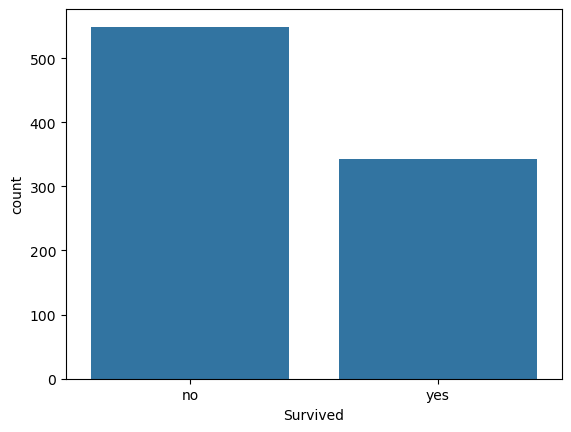

In [8]:
sns.countplot(data=df,x="Survived") #x=df["Survived"]

In [10]:
(df["Survived"].value_counts()/len(df))*100 # percentage count

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

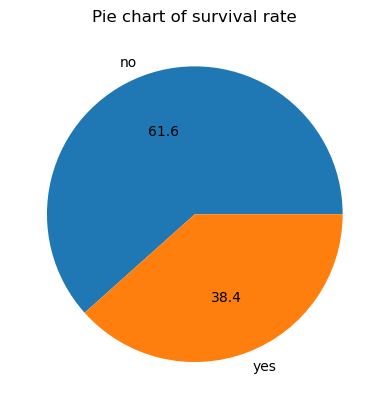

In [18]:
survived_count=df["Survived"].value_counts()
survived_label=df["Survived"].unique()

plt.pie(survived_count,labels=survived_label,autopct="%1.1f")
plt.title("Pie chart of survival rate")
plt.show()


### 6. Univariate Analysis( Categorical Value Analysis -2 )

<Axes: xlabel='Pclass', ylabel='count'>

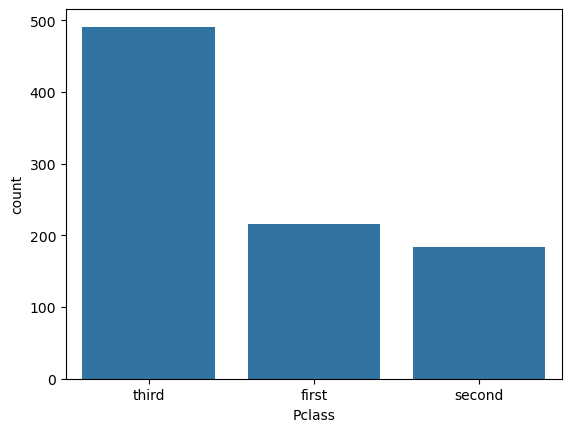

In [19]:
sns.countplot(data=df,x="Pclass")

In [21]:
(df["Pclass"].value_counts()/len(df))*100 # percentage count

Pclass
third     55.106622
first     24.242424
second    20.650954
Name: count, dtype: float64

<Axes: xlabel='Sex', ylabel='count'>

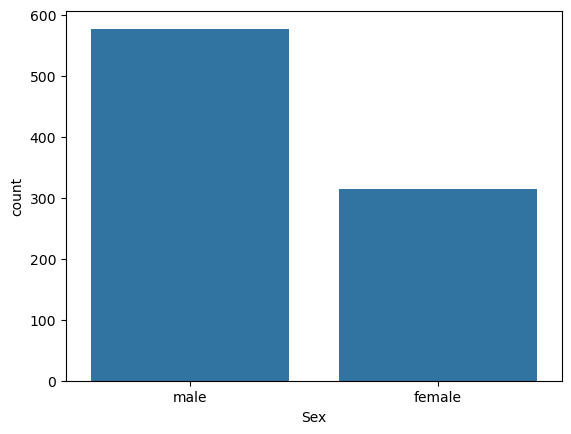

In [22]:
sns.countplot(data=df,x="Sex")

In [24]:
(df["Sex"].value_counts()/len(df))*100

Sex
male      64.758698
female    35.241302
Name: count, dtype: float64

<Axes: xlabel='Embarked', ylabel='count'>

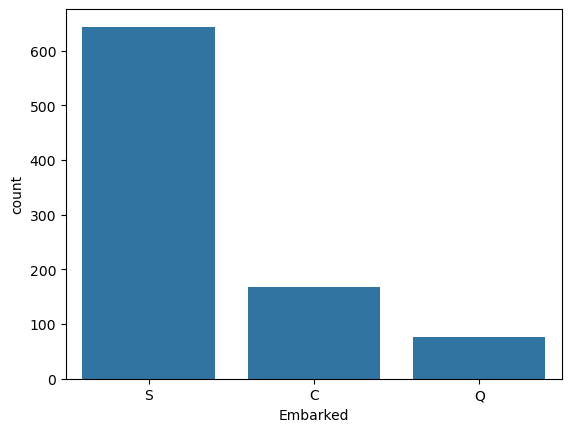

In [25]:
sns.countplot(data=df,x="Embarked")

In [26]:
(df["Embarked"].value_counts()/len(df))*100

Embarked
S    72.278339
C    18.855219
Q     8.641975
Name: count, dtype: float64

### 7. Univariate Analysis( Numerical Value Analysis -1 )

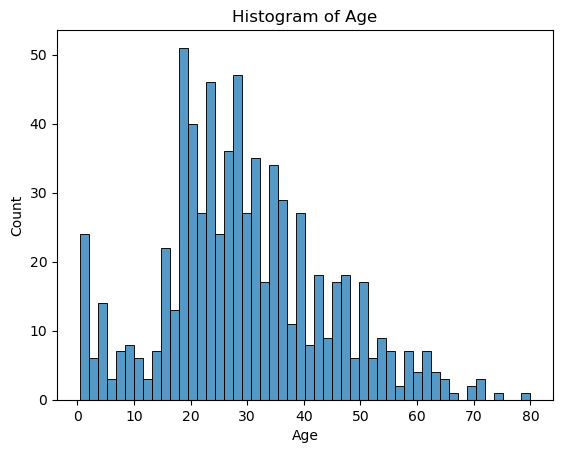

In [56]:
sns.histplot(df["Age"],bins=50) #sns.histplot(data=df,x="Age",bins=50)
plt.xlabel="Age"
plt.ylabel="Frequency"
plt.title("Histogram of Age")

plt.show()
#normal distribution

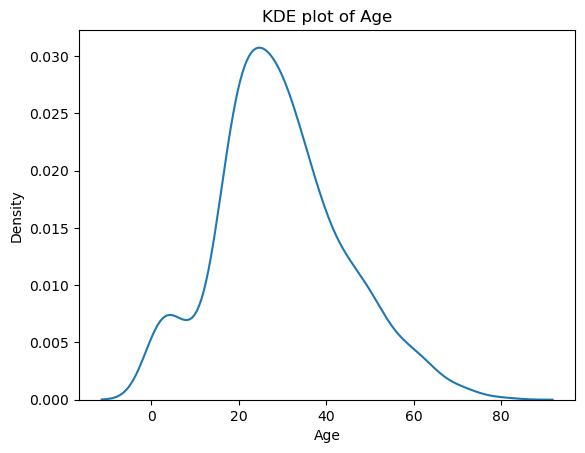

In [46]:
sns.kdeplot(df["Age"])
plt.xlabel="Age"
plt.ylabel="Probability Distribution"
plt.title("KDE plot of Age")
plt.show()

### 8. Univariate Analysis( Numerical Value Analysis -2 )

Text(0.5, 1.0, 'Histogram of Fare')

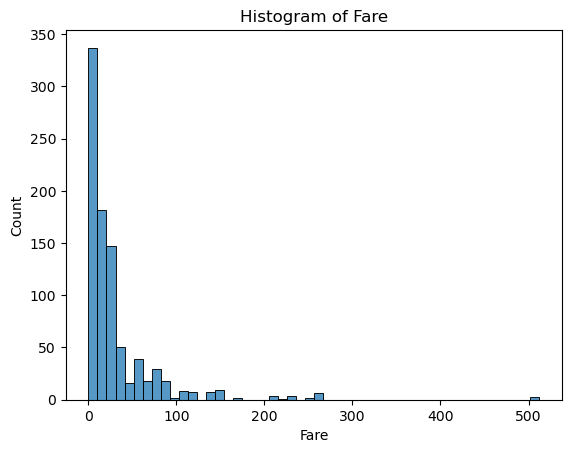

In [48]:
sns.histplot(df["Fare"],bins=50)
plt.xlabel="Fare"
plt.ylabel="Frequency"
plt.title("Histogram of Fare")
# skewed


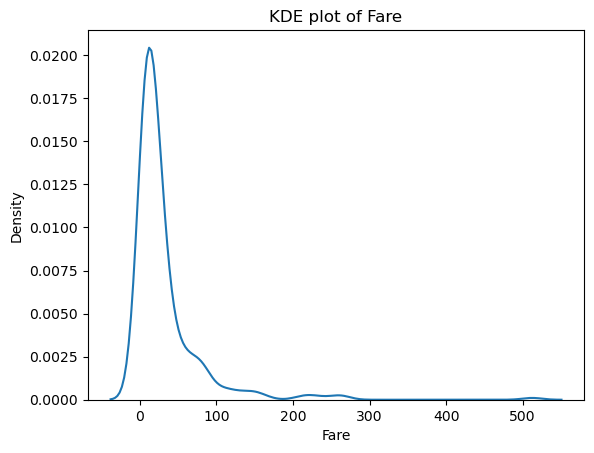

In [50]:
sns.kdeplot(df["Fare"])
plt.xlabel="Fare"
plt.ylabel="Probability Distribution"
plt.title("KDE plot of Fare")
plt.show()

<Axes: ylabel='Fare'>

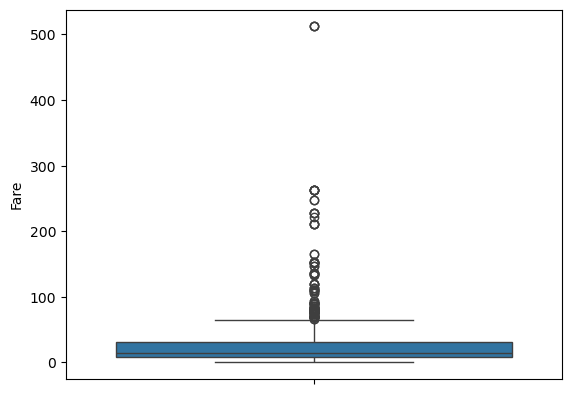

In [53]:
#use for outliers detection
sns.boxplot(df["Fare"])